# 01 - Análise Exploratória

**Objetivo:** entender a base de alunos de 2024 e o contexto disponível, e tomar as decisões de modelagem a partir dos dados.

**População:** alunos do 2º ano avaliados em 2024 (redes Estadual e Municipal) que fizeram a prova. Alunos ausentes foram excluídos na extração porque recebem `alfabetizado = 0` automaticamente (leakage, ver `images/leakage_presenca.png`).

**Perguntas da EDA:**
1. Como o target se distribui por UF e rede?
2. O contexto de escola do ano anterior é utilizável?
3. O contexto do ano anterior prevê o aluno?
4. As features de contexto são redundantes?
5. As variáveis do aluno variam o suficiente?

In [1]:
import sys
from pathlib import Path

# O notebook roda a partir de notebooks/, entao a raiz do projeto
# precisa entrar no sys.path para o import de src funcionar.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing.montagem import carregar_base
from src.visualization.graficos import salvar_figura

df = carregar_base()
print(df.shape)
df.head()

(1851828, 25)


,id_aluno,id_escola,id_municipio,sigla_uf,rede,serie,caderno,peso_aluno,alfabetizado,escola_alunos_2024,...,muni_participacao_estadual_2023,muni_taxa_publica_2023,muni_media_pt_publica_2023,muni_participacao_publica_2023,populacao_2022,pop_crescimento_2010_2022,alfabetizacao_15mais_2022,pib_per_capita_2022,pib_agro_pct_2021,pib_adm_publica_pct_2021
0,26012022,60011955,2608404,PE,Municipal,2,1,1.0,1,57,...,NaN,53.46,737.4392,NaN,13648,-0.53,72.80,9947.391559,12.583441,61.053885
1,26012905,60012706,2612307,PE,Municipal,2,1,1.0,1,14,...,NaN,58.09,756.0296,NaN,13836,-0.84,74.21,14159.439144,18.858199,50.665435
2,29157454,60015166,2922102,BA,Municipal,2,1,1.0,0,23,...,NaN,26.61,711.3384,NaN,17305,-2.81,81.67,10983.761919,18.165544,49.580635
3,31139995,60021428,3130101,MG,Municipal,2,1,1.0,1,21,...,NaN,51.87,743.6566,NaN,45847,2.31,95.21,26306.672192,10.079362,25.560410
4,51005072,60040461,5102504,MT,Municipal,2,1,1.0,0,73,...,NaN,47.53,739.6200,NaN,89681,0.17,92.24,26195.370257,14.101516,30.815080


In [2]:
for col in ["serie", "caderno", "rede"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).to_string())

print("\npeso_aluno:")
print(df["peso_aluno"].describe().to_string())
print(f"\nproporcao de pesos iguais a 1: {(df['peso_aluno'] == 1).mean():.2%}")


serie:
serie
2    1851828

caderno:
caderno
1     97138
3     93366
5     93351
2     93301
4     93242
7     93064
6     93049
15    86462
8     86290
20    85437
10    85391
9     85313
12    85278
13    85242
16    85207
11    85200
17    85194
21    85160
18    85106
19    85054
14    84971
43       12

rede:
rede
Municipal    1610754
Estadual      241074

peso_aluno:
count    1.851828e+06
mean     1.138956e+00
std      2.056983e-01
min      1.000000e+00
25%      1.030000e+00
50%      1.090000e+00
75%      1.190000e+00
max      2.983000e+01

proporcao de pesos iguais a 1: 23.99%


**Variáveis do aluno:**
- `serie` é constante (todos no 2º ano): **removida**.
- `peso_aluno` varia (só 24% iguais a 1, máximo ~30), mas é o peso amostral do INEP, não uma característica do aluno: **usado como `sample_weight`**, mesma metodologia do indicador oficial.

In [3]:
por_caderno = df.groupby("caderno")["alfabetizado"].mean()
print("Taxa de alfabetizacao por caderno:")
print(f"  minima: {por_caderno.min():.2%}  (caderno {por_caderno.idxmin()})")
print(f"  maxima: {por_caderno.max():.2%}  (caderno {por_caderno.idxmax()})")
print(f"  amplitude: {(por_caderno.max() - por_caderno.min()) * 100:.1f} pp")

print("\nTaxa de alfabetizacao por rede:")
print(df.groupby("rede")["alfabetizado"].agg(["mean", "size"]).to_string())

Taxa de alfabetizacao por caderno:
  minima: 50.00%  (caderno 43)
  maxima: 60.46%  (caderno 12)
  amplitude: 10.5 pp

Taxa de alfabetizacao por rede:
               mean     size
rede                        
Estadual   0.625368   241074
Municipal  0.593724  1610754


In [4]:
tabela_caderno = (
    df.groupby("caderno")["alfabetizado"]
    .agg(taxa="mean", alunos="size")
    .sort_values("alunos")
)
tabela_caderno["taxa"] = (tabela_caderno["taxa"] * 100).round(1)
print(tabela_caderno.to_string())

         taxa  alunos
caderno              
43       50.0      12
14       60.2   84971
19       59.7   85054
18       58.7   85106
21       59.9   85160
17       59.2   85194
11       59.8   85200
16       59.7   85207
13       60.4   85242
12       60.5   85278
9        59.7   85313
10       60.3   85391
20       59.1   85437
8        60.4   86290
15       59.1   86462
6        60.1   93049
7        60.0   93064
4        59.9   93242
2        59.3   93301
5        60.2   93351
3        59.4   93366
1        59.6   97138


**Caderno:** a amplitude aparente de 10,5 pp vem do caderno 43, com apenas 12 alunos. Nos 21 cadernos reais, a taxa vai de 58,7% a 60,5% (1,8 pp). As versões da prova são equivalentes, como esperado pela TRI: **`caderno` removido**.

**Rede:** Estadual 62,5% x Municipal 59,4%, com amostras grandes nos dois grupos: **`rede` mantida**.

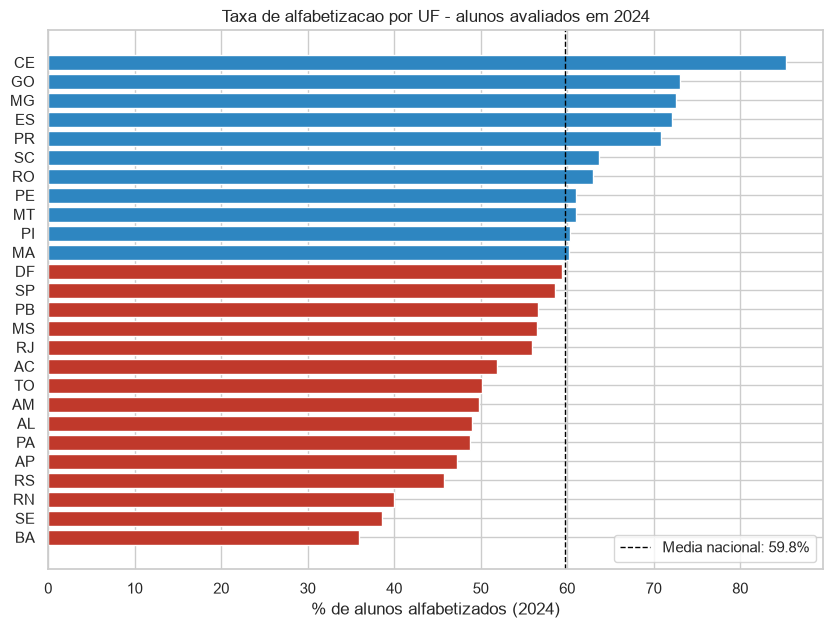

[OK] figura salva em images/eda_01_alfabetizacao_por_uf.png
Amplitude entre UFs: 49.4 pp


In [5]:
por_uf = df.groupby("sigla_uf")["alfabetizado"].mean().sort_values() * 100
media_nacional = df["alfabetizado"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 7))
cores = ["#c0392b" if v < media_nacional else "#2e86c1" for v in por_uf]
ax.barh(por_uf.index, por_uf.values, color=cores)
ax.axvline(media_nacional, color="black", linestyle="--", linewidth=1,
           label=f"Media nacional: {media_nacional:.1f}%")
ax.set_xlabel("% de alunos alfabetizados (2024)")
ax.set_title("Taxa de alfabetizacao por UF - alunos avaliados em 2024")
ax.legend(loc="lower right")
plt.show()

salvar_figura(fig, "eda_01_alfabetizacao_por_uf")
print(f"Amplitude entre UFs: {por_uf.max() - por_uf.min():.1f} pp")

**UF:** amplitude de 49,4 pp entre Ceará (85%) e Bahia (36%). O padrão não segue a divisão Norte/Nordeste x Sul/Sudeste: CE, PE, PI e MA estão acima da média, SP e RS abaixo. Hipótese compatível com os dados: política educacional pesa mais que região. **`sigla_uf` mantida.**

Achado de qualidade: Roraima (RR) não aparece entre os alunos avaliados de 2024 nas redes Estadual e Municipal.

## Validação do `id_escola` entre anos

A ideia inicial era usar a taxa de alfabetização da escola em 2023 como feature (turma anterior, sem leakage). Mas a curva escola 2023 x aluno 2024 saiu muito achatada (correlação 0,099, `images/eda_02`), mesmo em escolas grandes (`images/eda_03`), o que descartou ruído de amostra pequena.

Teste: uma escola não muda de município. Se o ID for o mesmo nos dois anos, deve estar no mesmo município.

In [6]:
from src.preprocessing.extracao import consultar

teste_id = consultar("""
    WITH e AS (
        SELECT DISTINCT
            CAST(ano AS varchar) AS ano,
            CAST(id_escola AS varchar) AS id_escola,
            CAST(id_municipio AS varchar) AS id_municipio
        FROM silver_alunos
    )
    SELECT
        COUNT(*) AS escolas_nos_dois_anos,
        SUM(CASE WHEN a.id_municipio = b.id_municipio THEN 1 ELSE 0 END) AS mesmo_municipio,
        SUM(CASE WHEN SUBSTR(a.id_municipio, 1, 2) = SUBSTR(b.id_municipio, 1, 2) THEN 1 ELSE 0 END) AS mesma_uf
    FROM e a
    JOIN e b
      ON a.id_escola = b.id_escola
     AND a.ano = '2023'
     AND b.ano = '2024'
""")
print(teste_id.to_string(index=False))

 escolas_nos_dois_anos  mesmo_municipio  mesma_uf
                 36462              865     29424


**Resultado:** dos 36.462 IDs presentes nos dois anos, só 865 (2,4%) estão no mesmo município, e 81% estão na mesma UF. O `id_escola` é **remascarado a cada ano**, aparentemente dentro de cada estado. O cruzamento com 2023 ligava cada aluno a uma escola aleatória da mesma UF, e o pouco sinal vinha só do efeito estado.

**Decisão:** histórico de escola descartado. Da escola, fica apenas o porte em 2024 (nº de alunos), conhecido antes da prova. O contexto passa a ser municipal, cujo código IBGE é estável.

Nulos na nova feature: 1.9%


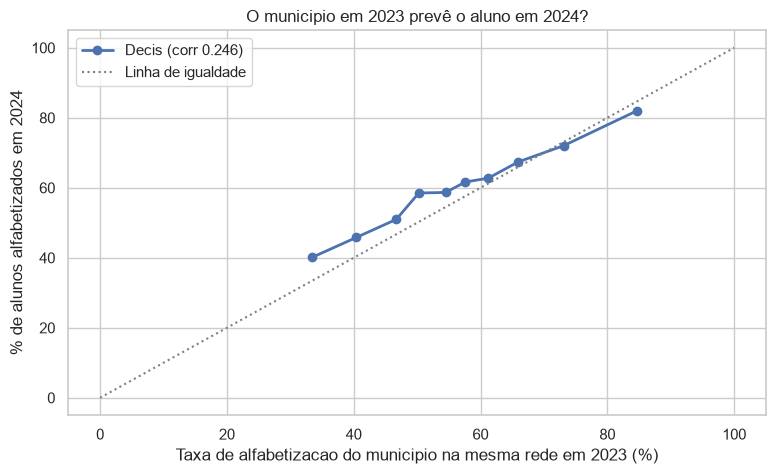

[OK] figura salva em images/eda_04_municipio_2023_vs_aluno_2024.png
muni_taxa_mesma_rede_2023
(3.4090000000000003, 37.87]    40.1
(37.87, 43.33]                 45.8
(43.33, 48.75]                 51.0
(48.75, 52.06]                 58.5
(52.06, 56.19]                 58.7
(56.19, 58.92]                 61.7
(58.92, 63.7]                  62.7
(63.7, 69.15]                  67.4
(69.15, 77.48]                 72.0
(77.48, 100.0]                 82.0


In [7]:
df["muni_taxa_mesma_rede_2023"] = (
    df["muni_taxa_municipal_2023"].where(df["rede"] == "Municipal",
                                         df["muni_taxa_estadual_2023"])
    .fillna(df["muni_taxa_publica_2023"])
)
print(f"Nulos na nova feature: {df['muni_taxa_mesma_rede_2023'].isna().mean():.1%}")

faixas = pd.qcut(df["muni_taxa_mesma_rede_2023"], q=10, duplicates="drop")
x = df.groupby(faixas, observed=True)["muni_taxa_mesma_rede_2023"].median()
y = df.groupby(faixas, observed=True)["alfabetizado"].mean() * 100
corr = df["muni_taxa_mesma_rede_2023"].corr(df["alfabetizado"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x.values, y.values, marker="o", linewidth=2, label=f"Decis (corr {corr:.3f})")
ax.plot([0, 100], [0, 100], color="gray", linestyle=":", label="Linha de igualdade")
ax.set_xlabel("Taxa de alfabetizacao do municipio na mesma rede em 2023 (%)")
ax.set_ylabel("% de alunos alfabetizados em 2024")
ax.set_title("O municipio em 2023 prevê o aluno em 2024?")
ax.legend()
plt.show()

salvar_figura(fig, "eda_04_municipio_2023_vs_aluno_2024")
print(y.round(1).to_string())

**Contexto municipal:** a taxa do município na mesma rede do aluno em 2023 acompanha de perto a linha de igualdade (correlação 0,246, de 40% a 82% entre os decis). O desempenho municipal é estável entre anos, o que permite antecipar risco. Comparado ao gráfico da escola, é a evidência visual do problema do ID.

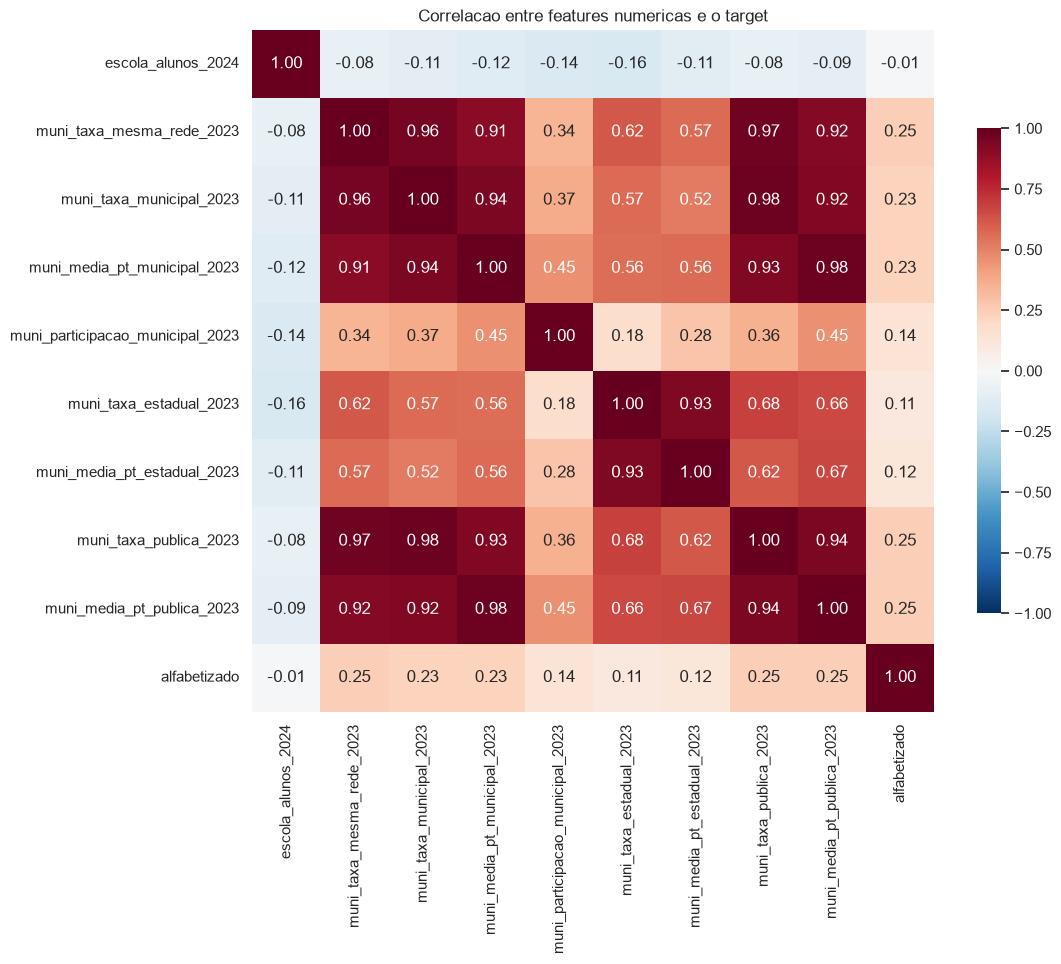

[OK] figura salva em images/eda_05_correlacao_features.png
Correlacao com o target (ordenada):
muni_media_pt_publica_2023          0.248
muni_taxa_publica_2023              0.248
muni_taxa_mesma_rede_2023           0.246
muni_media_pt_municipal_2023        0.232
muni_taxa_municipal_2023            0.232
muni_participacao_municipal_2023    0.140
muni_media_pt_estadual_2023         0.119
muni_taxa_estadual_2023             0.105
escola_alunos_2024                 -0.011


In [8]:
features_num = [
    "escola_alunos_2024",
    "muni_taxa_mesma_rede_2023",
    "muni_taxa_municipal_2023", "muni_media_pt_municipal_2023", "muni_participacao_municipal_2023",
    "muni_taxa_estadual_2023", "muni_media_pt_estadual_2023",
    "muni_taxa_publica_2023", "muni_media_pt_publica_2023",
]

corr_matriz = df[features_num + ["alfabetizado"]].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlacao entre features numericas e o target")
plt.show()
salvar_figura(fig, "eda_05_correlacao_features")

print("Correlacao com o target (ordenada):")
print(corr_matriz["alfabetizado"].drop("alfabetizado").sort_values(ascending=False).round(3).to_string())

**Redundância:** taxa e média de português da mesma rede têm correlação de 0,93 a 0,98, e as redes municipal e pública, 0,98. **Das 8 features municipais, ficam 2:** `muni_taxa_mesma_rede_2023` (resume as demais, 1,9% de nulos) e `muni_participacao_municipal_2023` (informação nova, correlação baixa com as outras).

In [9]:
print(f"Nulos em muni_taxa_mesma_rede_2023: {df['muni_taxa_mesma_rede_2023'].isna().mean():.1%}")

faixas_porte = pd.qcut(df["escola_alunos_2024"], q=10, duplicates="drop")
porte = df.groupby(faixas_porte, observed=True)["alfabetizado"].agg(taxa="mean", alunos="size")
porte["taxa"] = (porte["taxa"] * 100).round(1)
print(porte.to_string())

Nulos em muni_taxa_mesma_rede_2023: 1.9%
                    taxa  alunos
escola_alunos_2024              
(2.999, 24.0]       58.6  195761
(24.0, 36.0]        59.3  176258
(36.0, 47.0]        59.2  184215
(47.0, 56.0]        61.1  185751
(56.0, 68.0]        60.5  195585
(68.0, 80.0]        60.5  174982
(80.0, 94.0]        60.5  186098
(94.0, 114.0]       60.7  189550
(114.0, 146.0]      59.6  179292
(146.0, 441.0]      57.7  184336


**Porte da escola:** U invertido suave (57,7% a 61,1%), escolas muito pequenas e muito grandes um pouco abaixo. Efeito fraco e não linear: **mantido**, expectativa de baixa importância.

## Decisões para a modelagem

| Decisão | Motivo |
|---|---|
| Features: `rede`, `sigla_uf`, `escola_alunos_2024`, `muni_taxa_mesma_rede_2023`, `muni_participacao_municipal_2023` + dados externos | Resultado da EDA |
| `peso_aluno` como `sample_weight` | Metodologia oficial |
| Split estratificado, sem rebalanceamento | Classes 60/40, desbalanceamento leve |
| Imputação com indicador de nulo | Nulos concentrados por estado (DF, AC, SP) |
| Expectativa de AUC moderada | Sem dados individuais (LGPD), o modelo depende de contexto |

## Enriquecimento externo (IBGE)

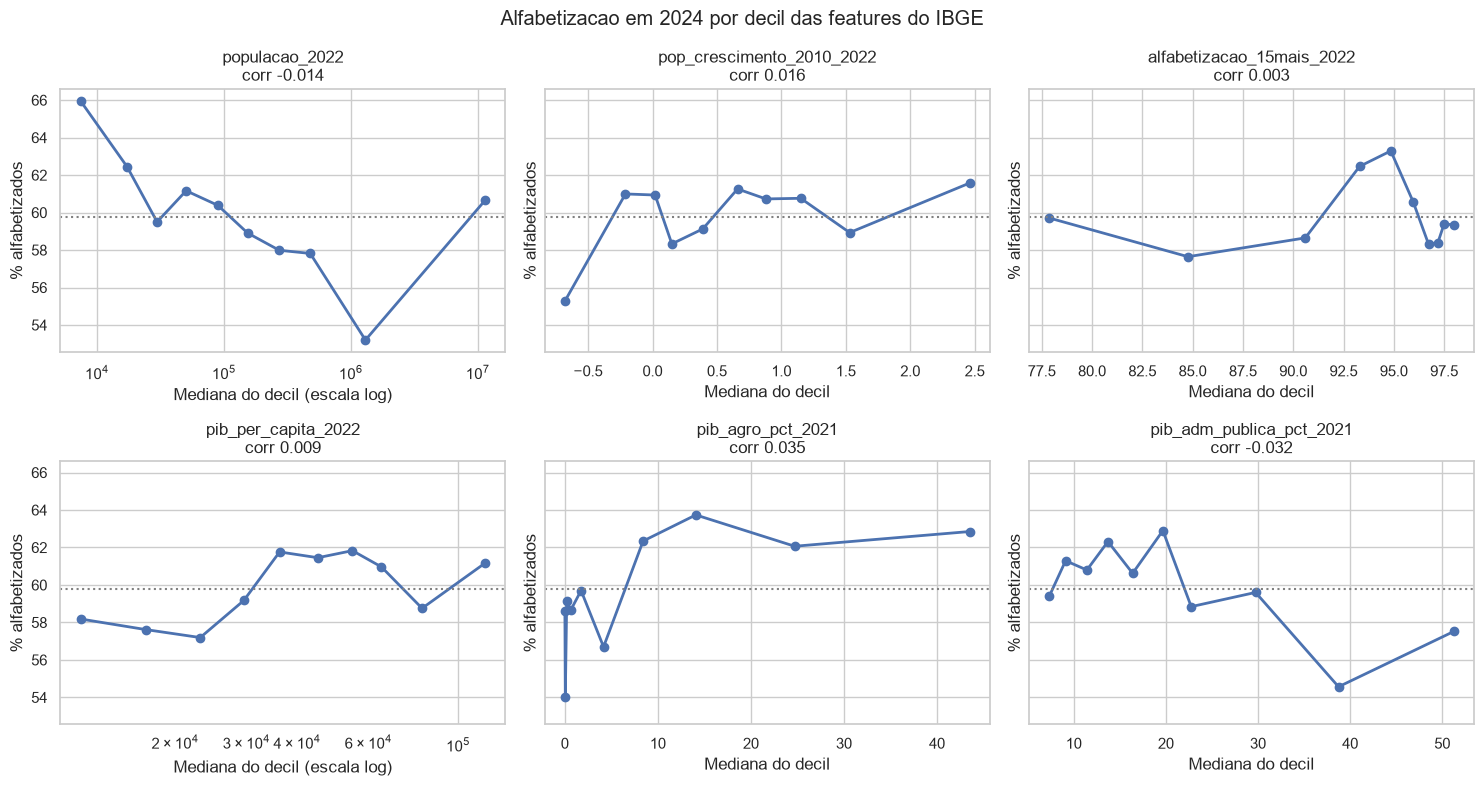

[OK] figura salva em images/eda_06_ibge_curvas_decis.png


WindowsPath('C:/Users/João Paulo/Desktop/Pessoal/Faculdade/fase-3/tech-challenge-fase3/images/eda_06_ibge_curvas_decis.png')

In [10]:
import matplotlib.pyplot as plt

from src.preprocessing.montagem import carregar_base
from src.preprocessing.features import criar_features, FEATURES_NUMERICAS
from src.visualization.graficos import curva_por_decis, heatmap_correlacao, salvar_figura

df = criar_features(carregar_base())

ibge = ["populacao_2022", "pop_crescimento_2010_2022", "alfabetizacao_15mais_2022",
        "pib_per_capita_2022", "pib_agro_pct_2021", "pib_adm_publica_pct_2021"]
escala_log = {"populacao_2022", "pib_per_capita_2022"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for col, ax in zip(ibge, axes.flat):
    curva_por_decis(df, col, ax=ax, log_x=col in escala_log)
fig.suptitle("Alfabetizacao em 2024 por decil das features do IBGE")
fig.tight_layout()
plt.show()
salvar_figura(fig, "eda_06_ibge_curvas_decis")

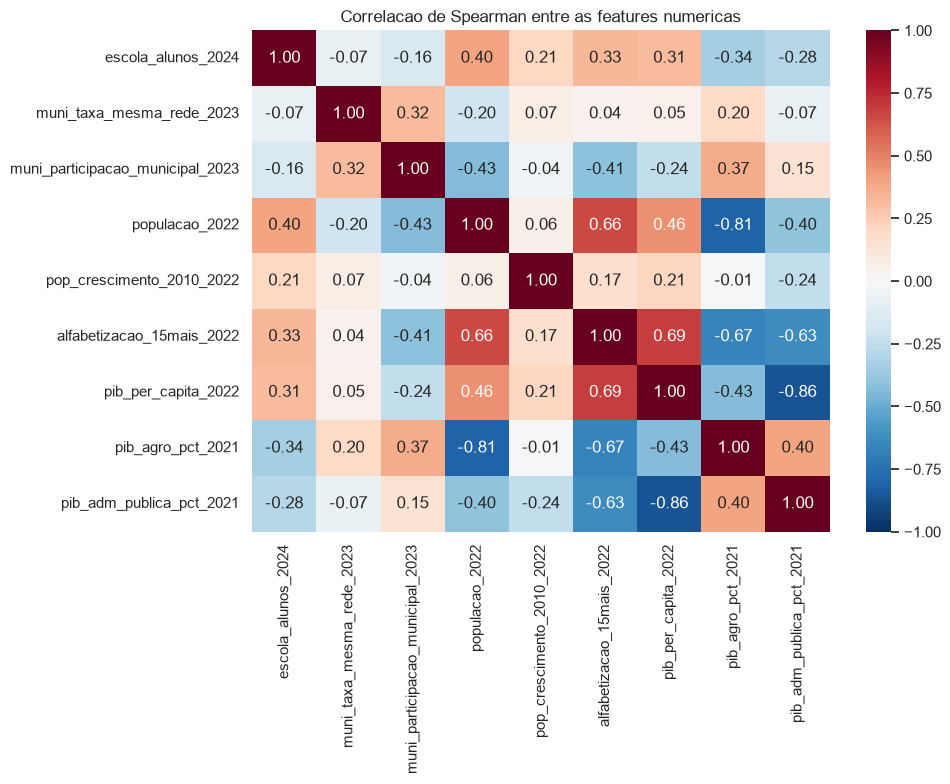

[OK] figura salva em images/eda_07_correlacao_features.png


WindowsPath('C:/Users/João Paulo/Desktop/Pessoal/Faculdade/fase-3/tech-challenge-fase3/images/eda_07_correlacao_features.png')

In [11]:
fig, ax = plt.subplots(figsize=(10, 8))
heatmap_correlacao(df, FEATURES_NUMERICAS, ax=ax)
ax.set_title("Correlacao de Spearman entre as features numericas")
fig.tight_layout()
plt.show()
salvar_figura(fig, "eda_07_correlacao_features")

In [12]:
# Nivel municipio: taxa de alfabetizacao dos alunos em 2024 x adultos em 2022
muni = (
    df.groupby("id_municipio")
    .agg(sigla_uf=("sigla_uf", "first"),
         taxa_2024=("alfabetizado", "mean"),
         alfab_adultos=("alfabetizacao_15mais_2022", "first"),
         alunos=("alfabetizado", "size"))
    .query("alunos >= 30")
)

nacional = muni["taxa_2024"].corr(muni["alfab_adultos"], method="spearman")
por_uf = (
    muni.groupby("sigla_uf")
    .apply(lambda g: g["taxa_2024"].corr(g["alfab_adultos"], method="spearman"))
    .sort_values()
)

print(f"Municipios analisados: {len(muni)}")
print(f"Correlacao nacional: {nacional:.3f}")
print(f"UFs com correlacao positiva: {(por_uf > 0).sum()} de {por_uf.notna().sum()}")
print(por_uf.round(2).to_string())

Municipios analisados: 4973
Correlacao nacional: 0.135
UFs com correlacao positiva: 12 de 25
sigla_uf
ES   -0.31
RJ   -0.25
AM   -0.25
GO   -0.22
RO   -0.20
CE   -0.20
SP   -0.19
PE   -0.19
MA   -0.16
MS   -0.11
AL   -0.09
MT   -0.06
PR   -0.01
RS    0.00
PI    0.03
BA    0.04
SC    0.05
SE    0.08
PB    0.10
RN    0.13
TO    0.16
PA    0.16
MG    0.17
AC    0.18
AP    0.19
DF     NaN


### Conclusoes do enriquecimento externo

**Fontes:** API de agregados do IBGE (SIDRA), chave codigo IBGE de 7 digitos, 100% dos 5.517 municipios dos alunos com correspondencia.

| Feature | Fonte | Observacao |
|---|---|---|
| populacao_2022 | Censo 2022 (t. 4709) | Municipios pequenos tem taxa maior (66% no menor decil); cidades de ~1 milhao, ~53% |
| pop_crescimento_2010_2022 | Censo 2022 (t. 4709) | Municipios que perderam populacao abaixo da media (55%) |
| alfabetizacao_15mais_2022 | Censo 2022 (t. 9543) | Sem relacao consistente com o resultado infantil (ver teste abaixo) |
| pib_per_capita_2022 | PIB dos Municipios (t. 5938) | PIB 2022 / populacao do Censo 2022, mesmo ano |
| pib_agro_pct_2021 | PIB dos Municipios (t. 5938) | VAB setorial so disponivel ate 2021; calculado como VAB agro / VAB total |
| pib_adm_publica_pct_2021 | PIB dos Municipios (t. 5938) | Proxy de dependencia da prefeitura; 1 municipio (GO) com VAB total negativo vira nulo |

**Decisoes:**
- As 6 features ficam. Correlacoes lineares com o target sao quase nulas, mas as curvas por decil mostram sinal nao linear (variacao de 53% a 66%).
- Sem redundancia pelo criterio da EDA (|corr| > 0,9): maior correlacao de Spearman e -0,86 (PIB per capita x administracao publica).
- Features correlacionadas dividem importancia no SHAP: ler a interpretabilidade considerando os pares fortes.

**Teste do paradoxo de Simpson (rejeitado):** a hipotese era que a alfabetizacao dos adultos teria relacao positiva dentro de cada UF e so se anularia no agregado nacional. Dentro das UFs a relacao e mista: positiva em 12 de 25, negativa em estados como SP, CE, PE e RJ. Nao ha regra geral.

**Insight:** o perfil socioeconomico do municipio explica pouco do resultado da alfabetizacao. A taxa municipal de 2023 tem correlacao de apenas 0,04 com a alfabetizacao dos adultos e 0,05 com o PIB per capita. Municipios semelhantes em riqueza e escolaridade tem resultados muito diferentes, o que aponta para gestao e politica educacional como alavanca.

**Implicacao para a modelagem:** relacoes nao monotonicas e dependentes da UF favorecem modelos de arvore em relacao a Regressao Logistica. O criterio definido antes dos resultados (ganho minimo de 2 pontos de ROC-AUC) vai confirmar ou nao.